# Extended Analysis NaCl

In [4]:
import trsfile
import matplotlib.pyplot as plt
import numpy as np
from tqdm import trange, tqdm
import seaborn as sns
import bokeh.plotting as bk
import lpips
import librosa
import torchaudio
import torch
import math

from skimage.metrics import structural_similarity as ssim

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error

import torch
import torch.nn.functional as F
import numpy as np

from bokeh.io import output_notebook 
output_notebook()

Loading BokehJS ...

## Loading the dataset

In [2]:
## Open the dataset
with trsfile.open('../../datasets/ota1/attack + affine_templates.trs', 'r') as traces:
    # Show all headers

    for header, value in traces.get_headers().items():
        print(header, '=', value)

        if str(header) == "Header.NUMBER_TRACES":
            nr_traces = value
        elif str(header) == "Header.NUMBER_SAMPLES":
            nr_samples = value
    print()

    trace_array = np.zeros((nr_traces, nr_samples))

    # Iterate over the first 11 traces
    for i, trace in enumerate(traces):
        print('Trace {0:d} contains {1:d} samples'.format(i, len(trace)))
        print('  - minimum value in trace: {0:f}'.format(min(trace)))
        print('  - maximum value in trace: {0:f}'.format(max(trace)))
        trace_array[i, :] = trace



sample_rate = 125e6 

# Split the target trace from the template traces
target_trace = trace_array[0, :]
raw_template_traces = trace_array[1:, :]

print(target_trace.shape) 

Header.NUMBER_TRACES = 11
Header.NUMBER_SAMPLES = 819170
Header.SAMPLE_CODING = SampleCoding.FLOAT
Header.LENGTH_DATA = 98
Header.TRACE_TITLE = trace
Header.LABEL_X = sec
Header.LABEL_Y = Volt
Header.SCALE_X = 2.4999948777804093e-07
Header.SCALE_Y = 0.015748031437397003
Header.TRACE_BLOCK = None

Trace 0 contains 819170 samples
  - minimum value in trace: -124.225807
  - maximum value in trace: -97.741936
Trace 1 contains 819170 samples
  - minimum value in trace: -124.580643
  - maximum value in trace: 0.000000
Trace 2 contains 819170 samples
  - minimum value in trace: -124.290321
  - maximum value in trace: 0.000000
Trace 3 contains 819170 samples
  - minimum value in trace: -124.193550
  - maximum value in trace: 0.000000
Trace 4 contains 819170 samples
  - minimum value in trace: -124.258064
  - maximum value in trace: 0.000000
Trace 5 contains 819170 samples
  - minimum value in trace: -124.483871
  - maximum value in trace: 0.000000
Trace 6 contains 819170 samples
  - minimum va

### Helper functions

In [8]:
# Function to cut off the "0 part" in template traces
def slice_trace(trace):
    idx = np.where(trace == 0)[0][0] # Get the first index where the power consumption = 0 [note, might not work for all datasets]
    new_trace = trace[:idx]
    return new_trace

def compute_correlation(target_trace, template_trace):
    corr = np.corrcoef(target_trace, template_trace)[0,1] # Take the non-identity part of the correlation matrix. Note that [0,1] = [1,0]
    return np.abs(corr)

def pattern_match(target_trace, template_trace, comparison_function, poi_start, poi_end, step=1):
    comparison_array = []
    window = poi_end - poi_start
    template_trace_sliced = template_trace[poi_start:poi_end]
    for timesample in trange(0, len(target_trace) - window, step):
        comparison = comparison_function(target_trace[timesample:timesample + window], template_trace_sliced)
        comparison_array.append(comparison)
    return np.array(comparison_array)

def determine_keybit(comparison_array0, comparison_array1, sign):
    # Get the highest peak of both, and take that timesample as comparison point
    if sign == "max":
        peak0 = np.max(comparison_array0)
        peak1 = np.max(comparison_array1)
        keybit_guess = np.argmax([peak0, peak1]) 
        print("Score bit 0: ", peak0)
        print("Score bit 1: ", peak1)
        timesample = np.argmax(comparison_array0) if keybit_guess == 0 else np.argmax(comparison_array1)
    elif sign == "min":
        peak0 = np.min(comparison_array0)
        peak1 = np.min(comparison_array1)
        keybit_guess = np.argmin([peak0, peak1]) 
        print("Score bit 0: ", peak0)
        print("Score bit 1: ", peak1)
        timesample = np.argmin(comparison_array0) if keybit_guess == 0 else np.argmin(comparison_array1)
    
    return int(keybit_guess), timesample

## Cut traces

In [9]:

# Cut off all 0 for each template trace
template_traces = np.zeros((10, np.where(raw_template_traces[0] == 0)[0][0]))

for i, trace in enumerate(raw_template_traces):
    new_trace = slice_trace(trace)
    template_traces[i] = new_trace



## Similarity based Attacks

In [10]:
def calc_spectrogram(trace, n_fft = 512): #NOTE: it is very sensitive for this value
    trace_tensor = torch.tensor(trace, dtype=torch.float32)
    spec = torchaudio.transforms.Spectrogram(n_fft=n_fft)(trace_tensor)
    spec_db = librosa.power_to_db(spec.numpy(), ref=np.max)

    # Normalize to [0,1]
    spec_db = (spec_db - spec_db.min()) / (spec_db.max() - spec_db.min() + 1e-8)

    return spec_db

def spec_to_tensor(spec_db, target_size):
    # Convert to 3-channel float32 tensor for LPIPS: (C, H, W)
    spec_tensor = torch.tensor(spec_db).unsqueeze(0).unsqueeze(0)  # (1,1,H,W)
    # Resize to target_size
    spec_resized = F.interpolate(spec_tensor, size=target_size, mode='bilinear', align_corners=False)

    return spec_resized

In [11]:
def compute_cosine(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)
    return cosine_similarity(x, y)[0, 0]

def compute_mse(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)

    return mean_squared_error(x, y)

def compute_psnr(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)

    mse = mean_squared_error(x, y)

    if mse == 0:
        return np.inf

    max_val = max(np.max(np.abs(x)), np.max(np.abs(y)))

    return 20 * np.log10(max_val / np.sqrt(mse))


def calc_spectrogram(trace, n_fft = 512): #NOTE: it is very sensitive for this value
    trace_tensor = torch.tensor(trace, dtype=torch.float32)
    spec = torchaudio.transforms.Spectrogram(n_fft=n_fft)(trace_tensor)
    spec_db = librosa.power_to_db(spec.numpy(), ref=np.max)

    # Normalize to [0,1]
    spec_db = (spec_db - spec_db.min()) / (spec_db.max() - spec_db.min() + 1e-8)

    return spec_db

def spec_to_tensor(spec_db, target_size):
    # Convert to 3-channel float32 tensor for LPIPS: (C, H, W)
    spec_tensor = torch.tensor(spec_db).unsqueeze(0).unsqueeze(0)  # (1,1,H,W)
    # Resize to target_size
    spec_resized = F.interpolate(spec_tensor, size=target_size, mode='bilinear', align_corners=False)

    return spec_resized

In [12]:
def plot_similarity(similarity_array0, similarity_array1, scalars, left, right, similarity_function):
        plt.figure(figsize=(10,5))
        plt.plot(similarity_array0, label = "bit 0")
        plt.plot(similarity_array1, label = "bit 1")
        plt.axvspan(left, right, alpha=0.2)
        plt.title("Similarity for template for {} on {}".format(scalars, similarity_function.__name__))
        plt.xlabel("Timesamples")
        plt.ylabel("Delta power consumption")
        plt.legend()
       # plt.savefig("./ota1_bitpos{}_{}.png".format(iteration, similarity_function.__name__), bbox_inches='tight')
        plt.show()

<function compute_cosine at 0x137f1aca0> max


100%|██████████| 128402/128402 [01:16<00:00, 1680.98it/s]


Score bit 0:  1.0000002
Score bit 1:  1.0000002


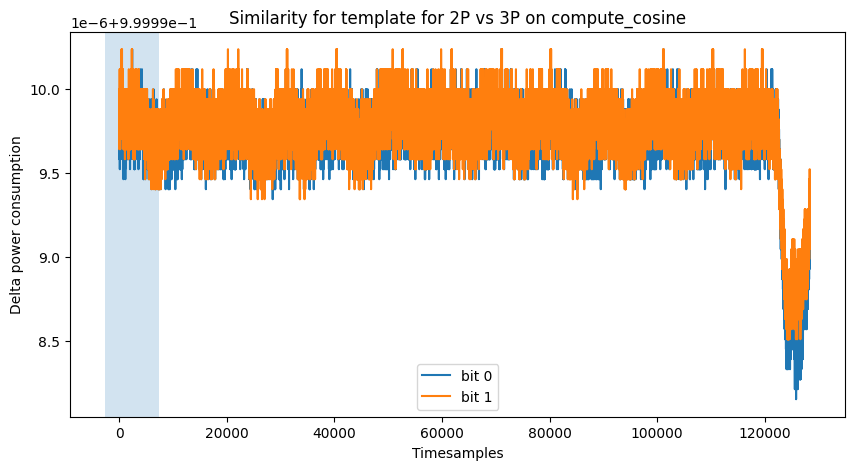

Current scalar value: 2
Recovered keybit:  0
<function compute_cosine at 0x137f1aca0> max


100%|██████████| 170402/170402 [01:38<00:00, 1733.74it/s]


Score bit 0:  1.0000004
Score bit 1:  1.0000001


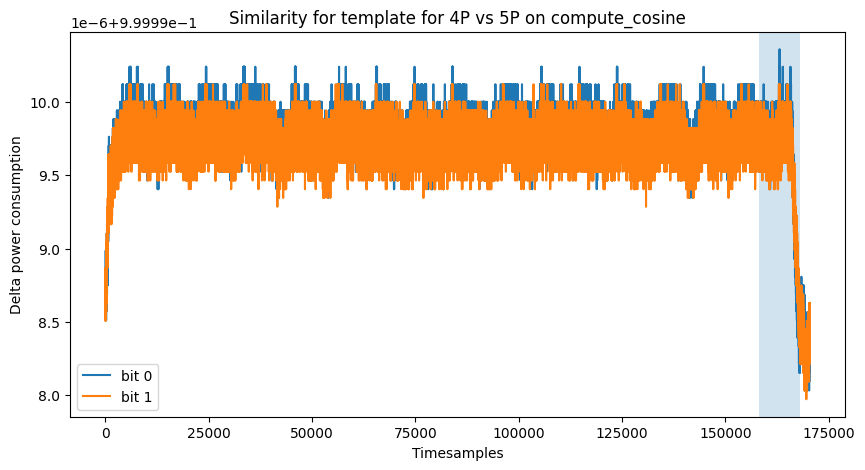

Current scalar value: 4
Recovered keybit:  0
<function compute_cosine at 0x137f1aca0> max


100%|██████████| 171402/171402 [01:38<00:00, 1737.29it/s]


Score bit 0:  1.0000002
Score bit 1:  1.0000002


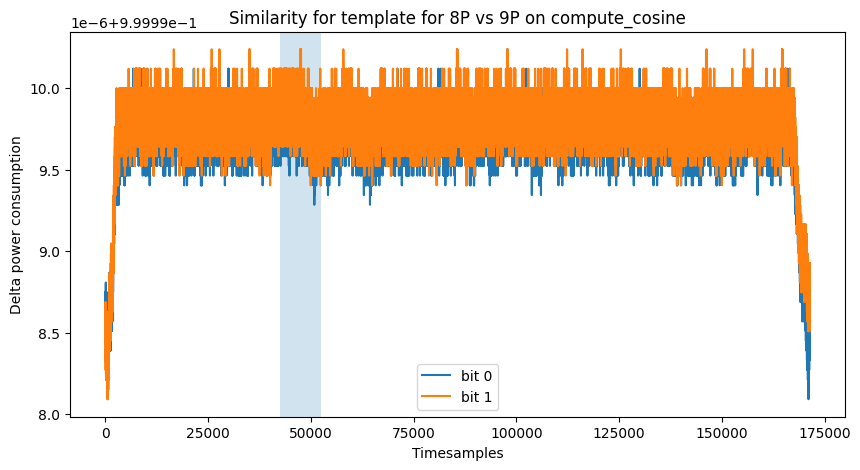

Current scalar value: 8
Recovered keybit:  0
<function compute_cosine at 0x137f1aca0> max


100%|██████████| 173402/173402 [01:36<00:00, 1799.74it/s]


Score bit 0:  1.0000002
Score bit 1:  1.0000002


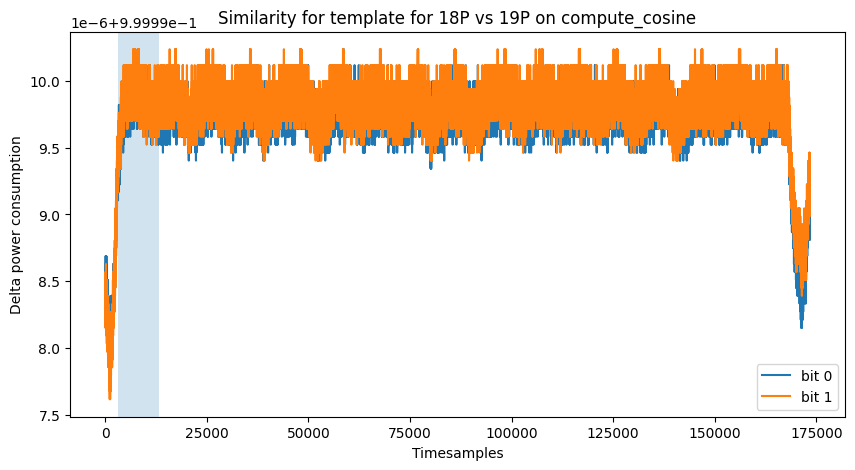

Current scalar value: 16
Recovered keybit:  0
<function compute_cosine at 0x137f1aca0> max


100%|██████████| 133402/133402 [01:12<00:00, 1839.28it/s]


Score bit 0:  1.0000002
Score bit 1:  1.0000002


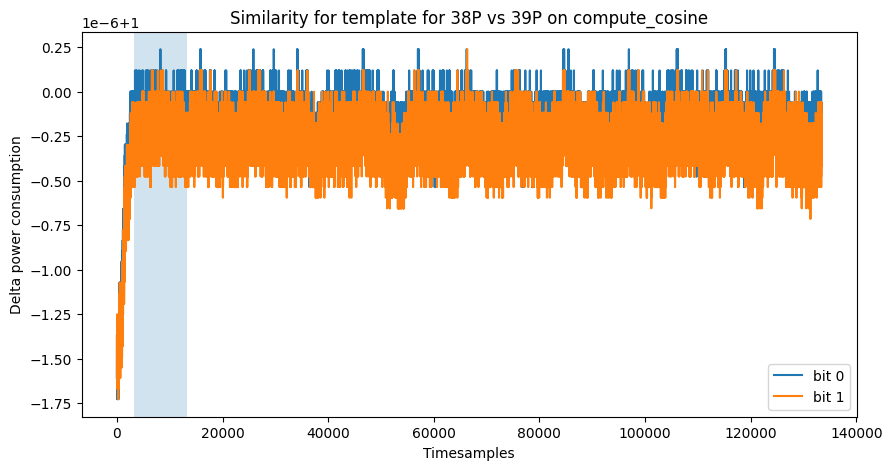

Current scalar value: 32
Recovered keybit:  0
<function compute_mse at 0x137f1ae80> min


100%|██████████| 128402/128402 [01:02<00:00, 2058.21it/s]


Score bit 0:  0.004988483153283596
Score bit 1:  0.006905797403305769


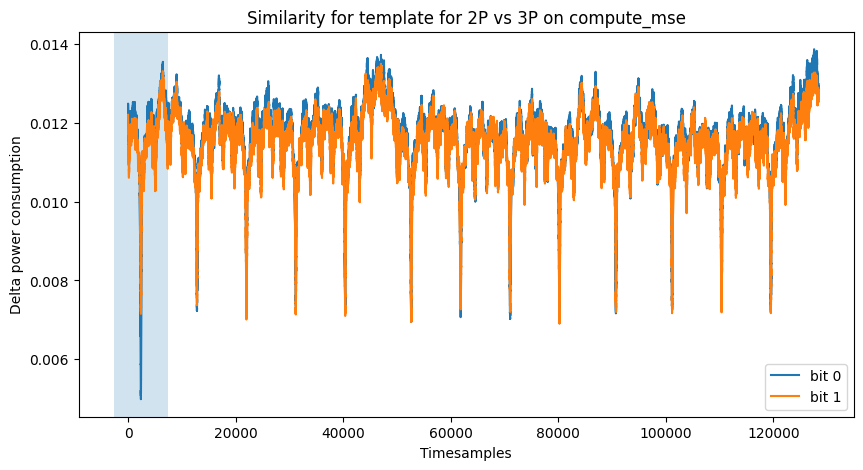

Current scalar value: 2
Recovered keybit:  0
<function compute_mse at 0x137f1ae80> min


100%|██████████| 170402/170402 [01:22<00:00, 2054.08it/s]


Score bit 0:  0.00455830292776227
Score bit 1:  0.00695142662152648


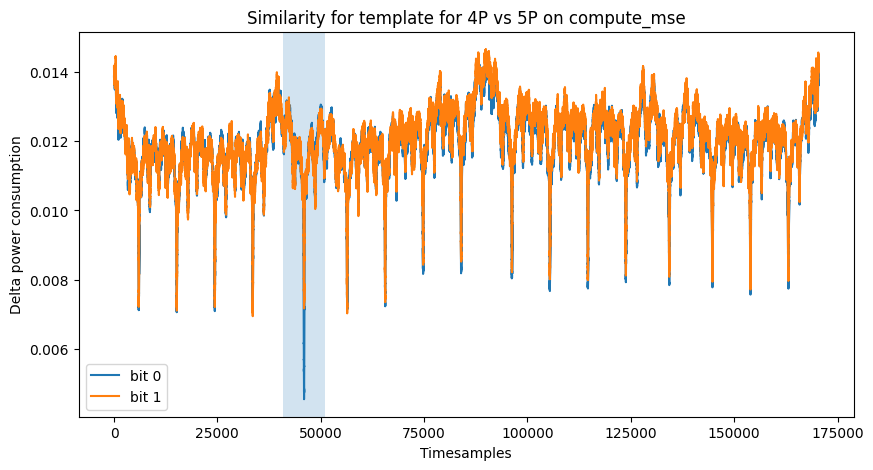

Current scalar value: 4
Recovered keybit:  0
<function compute_mse at 0x137f1ae80> min


100%|██████████| 171402/171402 [01:23<00:00, 2058.32it/s]


Score bit 0:  0.007066776510328054
Score bit 1:  0.0044286479242146015


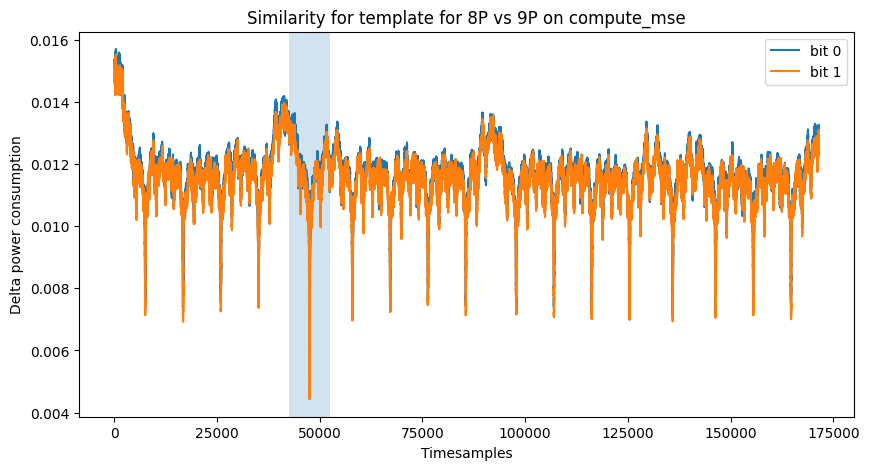

Current scalar value: 9
Recovered keybit:  1
<function compute_mse at 0x137f1ae80> min


100%|██████████| 173402/173402 [01:22<00:00, 2099.01it/s]


Score bit 0:  0.006825528107583523
Score bit 1:  0.004749842453747988


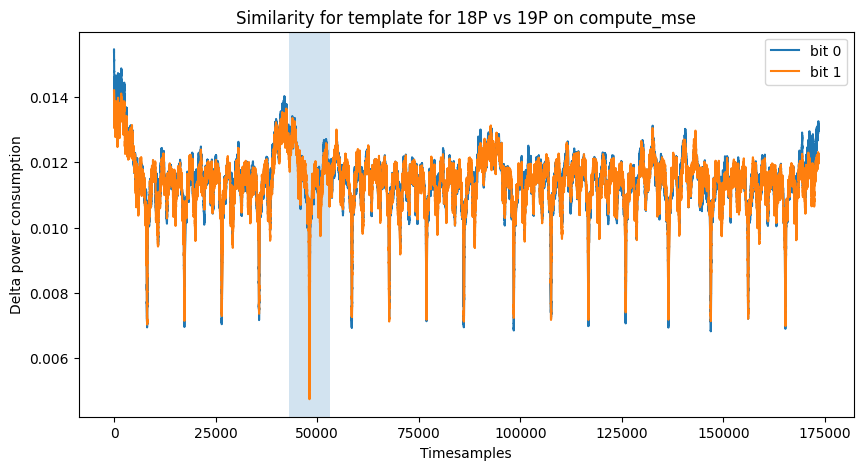

Current scalar value: 19
Recovered keybit:  1
<function compute_mse at 0x137f1ae80> min


100%|██████████| 133402/133402 [01:04<00:00, 2081.13it/s]


Score bit 0:  0.00452836649492383
Score bit 1:  0.006774387322366238


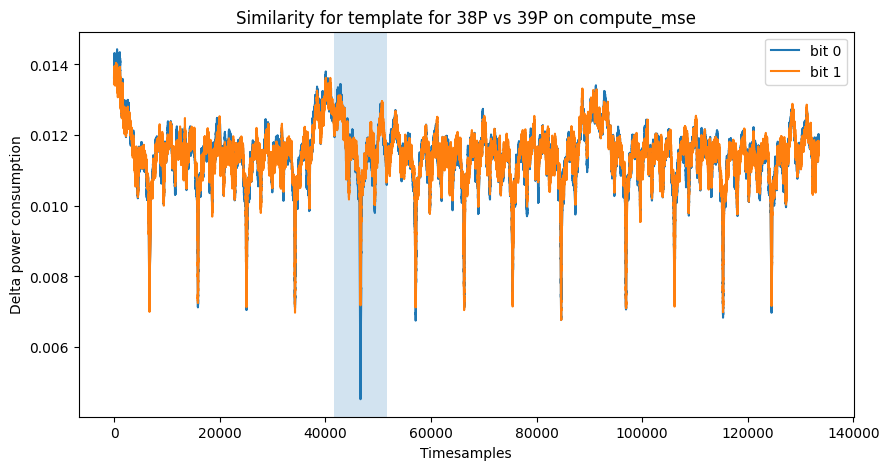

Current scalar value: 38
Recovered keybit:  0
<function compute_psnr at 0x137f1b380> max


100%|██████████| 128402/128402 [01:03<00:00, 2029.07it/s]


Score bit 0:  23.020314901086508
Score bit 1:  21.607861667796406


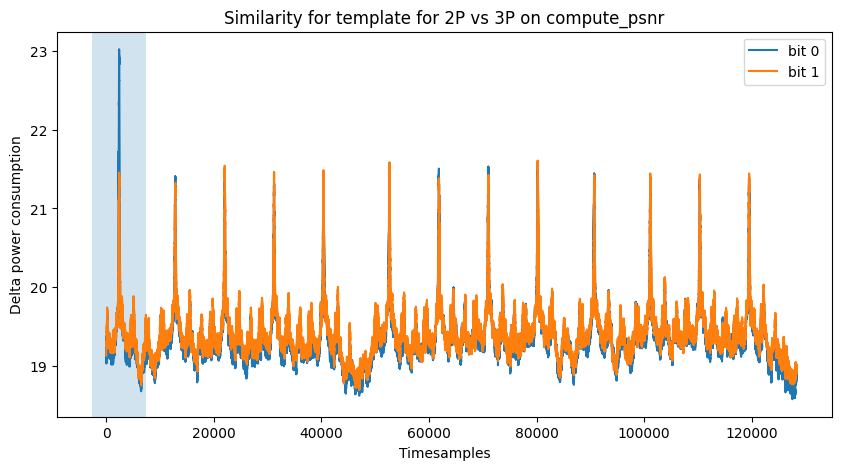

Current scalar value: 2
Recovered keybit:  0
<function compute_psnr at 0x137f1b380> max


100%|██████████| 170402/170402 [01:23<00:00, 2038.32it/s]


Score bit 0:  23.41196816609793
Score bit 1:  21.579260572407243


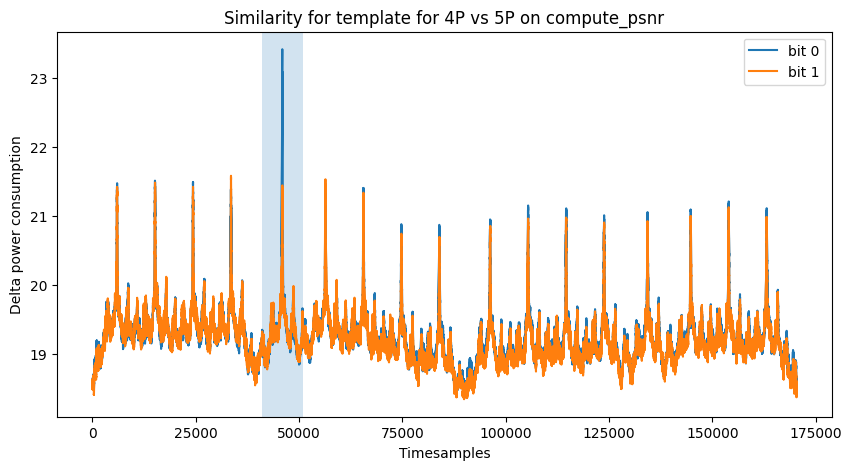

Current scalar value: 4
Recovered keybit:  0
<function compute_psnr at 0x137f1b380> max


100%|██████████| 171402/171402 [01:23<00:00, 2041.24it/s]


Score bit 0:  21.507786432071477
Score bit 1:  23.537288445850937


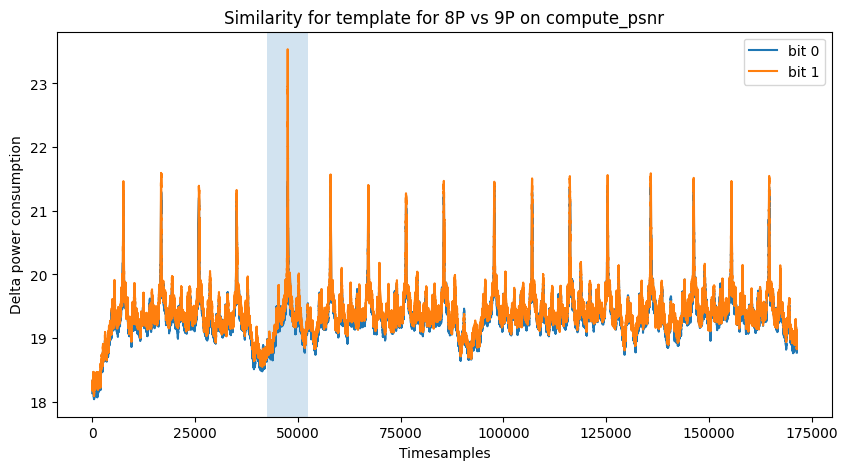

Current scalar value: 9
Recovered keybit:  1
<function compute_psnr at 0x137f1b380> max


100%|██████████| 173402/173402 [01:25<00:00, 2016.48it/s]


Score bit 0:  21.658637405749275
Score bit 1:  23.23320795133577


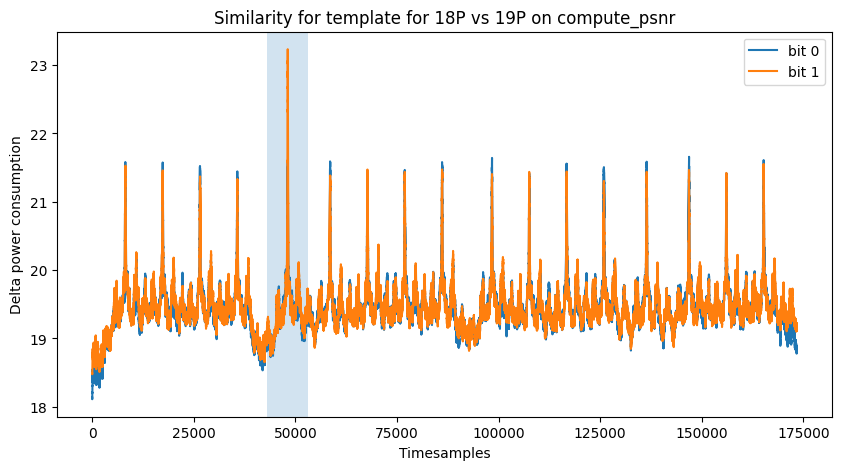

Current scalar value: 19
Recovered keybit:  1
<function compute_psnr at 0x137f1b380> max


100%|██████████| 133402/133402 [01:05<00:00, 2029.19it/s]


Score bit 0:  23.440584315808366
Score bit 1:  21.69129976401521


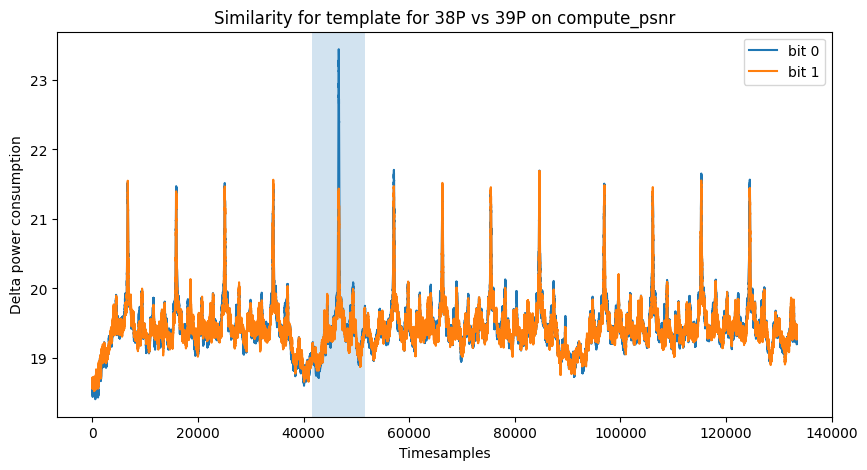

Current scalar value: 38
Recovered keybit:  0
The correct key: 100110
Recovered key using compute_cosine: [1. 0. 0. 0. 0. 0.]
Recovered key using compute_mse: [1. 0. 0. 1. 1. 0.]
Recovered key using compute_psnr: [1. 0. 0. 1. 1. 0.]


In [14]:
# Do the sequential key bit recovery
keybits = 5
step_size = 1
similarity_methods = [compute_cosine,
    compute_mse,
    compute_psnr]
scalars = ["2P vs 3P", "4P vs 5P", "8P vs 9P", "18P vs 19P", "38P vs 39P"]

poi_start = 2024  # This window determined by pattern identification, such as e.g. autocorrelation (used in the original OTA paper)
poi_end = 8622
window = poi_end - poi_start

recovered_key = np.ones(shape=(len(similarity_methods), keybits + 1))  # Initialize with ones to set the first bit for each method to 1

valleys = [0, 135000, 312000, 490000, 670000, 810000] # using SPA to speed up computation time

# Perform pattern matching based on different similarity methods
for j, method in enumerate(similarity_methods):
    scalar = 1
    for iteration, keybit_to_guess in enumerate(range(0, keybits*2, 2)):

        if method.__name__ == "compute_mse":
            sign = "min"
        else:
            sign = "max"

        print(method, sign)

        # Create templates from the collected traces
        template0 = template_traces[keybit_to_guess, :]
        template1 = template_traces[keybit_to_guess+1, :]

        # Select current window to attack based on SPA. Only done to speed up computation time
        start_window = valleys[iteration]
        end_window = valleys[iteration + 1]

        # Slice target trace based on the window where we attack
        target_slice = target_trace[start_window:end_window]

        similarity_array0 = pattern_match(target_slice, template0, method, poi_start, poi_end, step=step_size)
        similarity_array1 = pattern_match(target_slice, template1, method, poi_start, poi_end, step=step_size)

        np.savez("./analysis similarities/ota1_bitpos{}_{}.npz".format(iteration, method.__name__), comparison_0 = similarity_array0, comparison_1 = similarity_array1)

        best_keyguess, timesample  = determine_keybit(similarity_array0, similarity_array1, sign=sign)

        plot_similarity(similarity_array0, similarity_array1, scalars[iteration], timesample-5000, timesample+5000, method)

        recovered_key[j, iteration+1] = best_keyguess
        scalar = (scalar << 1) | best_keyguess
        print("Current scalar value: " + str(scalar))
        print("Recovered keybit: ", best_keyguess)

print("The correct key: 100110")

for nr, sim_method in enumerate(similarity_methods):
    print(f"Recovered key using {sim_method.__name__}: " + str(recovered_key[nr]))